<a href="https://colab.research.google.com/github/Mich-088/MAT422/blob/main/Homework_3_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 3.7

  **3.7 Neural Networks -** Artificial neural networks is a collection connected layers of units or nodes to loosely model the neurons in a biological brain.

* <span style="color:green">**3.7.1. Mathematical formulation**</span>

* <span style="color:green">**3.7.2. Activation functions**</span>

* <span style="color:green">**3.7.3. Cost function**</span>

* <span style="color:green">**3.7.4. Backpropagation**</span>

* <span style="color:green">**3.7.5. Backpropagation algorithm**</span>



---



In [37]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
rng = np.random.default_rng(422)

---


**Mathematical formulation**





In [38]:
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1 = rng.normal(scale=0.5, size=(2, 3))
b1 = np.zeros((1, 3))
W2 = rng.normal(scale=0.5, size=(3, 1))
b2 = np.zeros((1, 1))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

_, hidden, _, output = forward(X)
print("Hidden layer values:")
print(hidden)
print("Initial predicted probabilities:")
print(output)

Hidden layer values:
[[ 0.       0.       0.     ]
 [-0.69724 -0.11969  0.44297]
 [ 0.76367  0.25701  0.32008]
 [ 0.14209  0.14167  0.6683 ]]
Initial predicted probabilities:
[[0.5    ]
 [0.58828]
 [0.41711]
 [0.49511]]


---


**Activation functions**

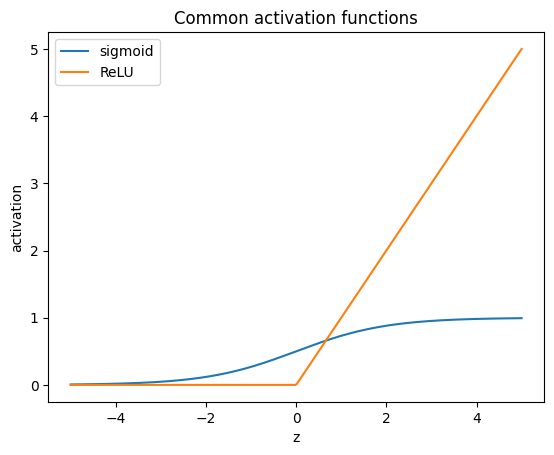

In [39]:
def relu(z):
    return np.maximum(0, z)

z = np.linspace(-5, 5, 300)
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, relu(z), label="ReLU")
plt.xlabel("z")
plt.ylabel("activation")
plt.title("Common activation functions")
plt.legend()
plt.show()

---


**Cost function**

In [40]:
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-9
    return -np.mean(y_true*np.log(y_prob + eps) + (1-y_true)*np.log(1-y_prob + eps))

_, _, _, output = forward(X)
print("Initial binary cross-entropy =", binary_cross_entropy(y, output))
print("Target values:", y.ravel())
print("Initial predicted probabilities:", output.ravel())

Initial binary cross-entropy = 0.6953799446372811
Target values: [0. 1. 1. 0.]
Initial predicted probabilities: [0.5     0.58828 0.41711 0.49511]


---


**Backpropagation**

In [41]:
z1, a1, z2, a2 = forward(X)
dz2 = (a2 - y) / len(X)
dW2 = a1.T @ dz2
db2 = dz2.sum(axis=0, keepdims=True)
da1 = dz2 @ W2.T
dz1 = da1 * (1 - np.tanh(z1)**2)
dW1 = X.T @ dz1
db1 = dz1.sum(axis=0, keepdims=True)

print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("Backpropagation sends the output error backward through W2 and the tanh derivative.")

dW2 shape: (3, 1)
db2 shape: (1, 1)
dW1 shape: (2, 3)
db1 shape: (1, 3)
Backpropagation sends the output error backward through W2 and the tanh derivative.


---


**Backpropagation algorithm**

Final probabilities:
[[0.00031]
 [0.9969 ]
 [0.99683]
 [0.00411]]
Final predictions: [0 1 1 0]


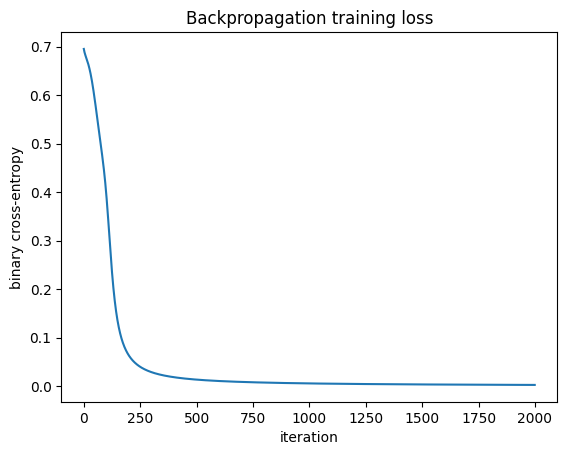

In [42]:
learning_rate = 0.5
losses = []
for step in range(2000):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    losses.append(binary_cross_entropy(y, a2))

    dz2 = (a2 - y) / len(X)
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - np.tanh(z1)**2)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

_, _, _, final_output = forward(X)
print("Final probabilities:")
print(final_output)
print("Final predictions:", (final_output > 0.5).astype(int).ravel())

plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("binary cross-entropy")
plt.title("Backpropagation training loss")
plt.show()